# Selecting, Filtering, and Indexing Data in Pandas

Most questions start with a selection: some columns, the rows that meet a condition, a range of dates. pandas has two explicit indexers, `loc` (by **label**) and `iloc` (by **position**), plus boolean filters and `query`.

**After this lesson you can:**

1. Select columns and rows with `[]`, `loc` and `iloc`.
2. Filter rows with boolean conditions, `isin`, `between` and `query`.
3. Use a meaningful index (`set_index`, `sort_index`) for fast label lookups.
4. Find the largest or smallest values, and assign values safely with `loc`.

**Data:** NYC yellow taxi trips, January 2024 (about 3 million trips), and the taxi zone lookup table.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"]
trips = pd.read_parquet(datasets.taxi("2024-01"), columns=COLS)
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
print(f"{len(trips):,} trips, {trips.shape[1]} columns, {trips.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
trips.head(3)

2,964,624 trips, 10 columns, 213 MB in memory


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,total_amount
0,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,186,79,2,17.7,0.00,22.70
1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,140,236,1,10.0,3.75,18.75
2,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,236,79,1,23.3,3.00,31.30


## 1. Columns

- `df["col"]` returns a Series; `df[["a", "b"]]` returns a DataFrame.
- `df.filter(like="amount")` selects columns by a name pattern.
- `df.select_dtypes("number")` selects columns by type.

In [2]:
print(trips["fare_amount"].head(3).tolist())
print(list(trips[["trip_distance", "fare_amount"]].columns))
print(list(trips.filter(like="amount").columns))
print(list(trips.select_dtypes("datetime").columns))

[17.7, 10.0, 23.3]
['trip_distance', 'fare_amount']
['fare_amount', 'tip_amount', 'total_amount']
['tpep_pickup_datetime', 'tpep_dropoff_datetime']


## 2. `loc` and `iloc`

| Indexer | Selects by | Slice end | Example |
| :--- | :--- | :--- | :--- |
| `df.loc[rows, cols]` | labels and boolean masks | **included** | `df.loc[0:4, "fare_amount"]` |
| `df.iloc[rows, cols]` | integer positions | excluded | `df.iloc[0:5, 7]` |

In [3]:
print(trips.loc[0:2, ["trip_distance", "fare_amount"]], "\n")       # labels 0, 1, 2 (end included)
print(trips.iloc[0:2, [3, 7]], "\n")                                 # positions 0, 1 (end excluded)
print("last row, last column:", trips.iloc[-1, -1])

   trip_distance  fare_amount
0           1.72         17.7
1           1.80         10.0
2           4.70         23.3 

   trip_distance  fare_amount
0           1.72         17.7
1           1.80         10.0 

last row, last column: 55.88


## 3. Boolean Filters

Combine conditions with `&`, `|`, `~` and parentheses. `isin` tests membership; `between` tests a range (both ends included by default). `query` writes the same filter as a string, which is often easier to read; `@name` refers to a Python variable.

In [4]:
long_trips = trips[(trips["trip_distance"] > 20) & (trips["fare_amount"] > 0)]
airports = zones.loc[zones["Zone"].str.contains("Airport"), "LocationID"].tolist()
from_airport = trips[trips["PULocationID"].isin(airports)]
evening = trips[trips["tpep_pickup_datetime"].dt.hour.between(17, 19)]
min_tip = 20
big_tippers = trips.query("tip_amount >= @min_tip and payment_type == 1")

print(f"trips longer than 20 miles : {len(long_trips):>9,}")
print(f"airport zones {airports} -> pickups: {len(from_airport):,} ({len(from_airport) / len(trips):.1%})")
print(f"pickups 17:00-19:59        : {len(evening):>9,}")
print(f"card tips of $20 or more   : {len(big_tippers):>9,}")

trips longer than 20 miles :    28,944
airport zones [1, 132, 138] -> pickups: 235,068 (7.9%)
pickups 17:00-19:59        :   603,077
card tips of $20 or more   :    18,821


## 4. A Meaningful Index

The default index is 0, 1, 2, ... A meaningful index (an id, a date, a zone) makes lookups by label fast and readable. A **sorted** index allows label slices, for example a range of timestamps.

In [5]:
z = zones.set_index("LocationID")
print(z.loc[[132, 138, 161], ["Borough", "Zone"]], "\n")       # JFK, LaGuardia, Midtown Center

by_time = trips.set_index("tpep_pickup_datetime").sort_index()
new_year_hour = by_time.loc["2024-01-01 00:00":"2024-01-01 00:59"]
print(f"trips picked up in the first hour of 2024: {len(new_year_hour):,}")

t = time.perf_counter()
for _ in range(200):
    by_time.loc["2024-01-15 08:00":"2024-01-15 08:05"]
t_index = (time.perf_counter() - t) / 200 * 1000
t = time.perf_counter()
for _ in range(20):
    trips[trips["tpep_pickup_datetime"].between("2024-01-15 08:00", "2024-01-15 08:05:59")]
t_mask = (time.perf_counter() - t) / 20 * 1000
print(f"5-minute window: sorted index {t_index:.2f} ms vs boolean mask {t_mask:.1f} ms")

              Borough               Zone
LocationID                              
132            Queens        JFK Airport
138            Queens  LaGuardia Airport
161         Manhattan     Midtown Center 



trips picked up in the first hour of 2024: 6,596


5-minute window: sorted index 0.37 ms vs boolean mask 16.0 ms


A slice on a sorted index uses binary search ($O(\log n)$); a boolean mask compares every row ($O(n)$).

## 5. Largest, Smallest, Sorted

In [6]:
print(trips.nlargest(3, "tip_amount")[["trip_distance", "fare_amount", "tip_amount"]], "\n")
print(trips.sort_values(["PULocationID", "fare_amount"], ascending=[True, False]).head(3)[["PULocationID", "fare_amount"]], "\n")
top_zones = trips["PULocationID"].value_counts().head(8)
top_zones.index = z.loc[top_zones.index, "Zone"]
print(top_zones)

         trip_distance  fare_amount  tip_amount
2575154           0.00         0.01       428.0
887077            4.21        22.60       422.7
649083            3.92        17.70       303.0 



         PULocationID  fare_amount
424330              1       267.94
1494627             1       250.00
1398730             1       208.00 

Zone
JFK Airport                     145240
Midtown Center                  143471
Upper East Side South           142708
Upper East Side North           136465
Midtown East                    106717
Times Sq/Theatre District       106324
Penn Station/Madison Sq West    104523
Lincoln Square East             104080
Name: count, dtype: int64


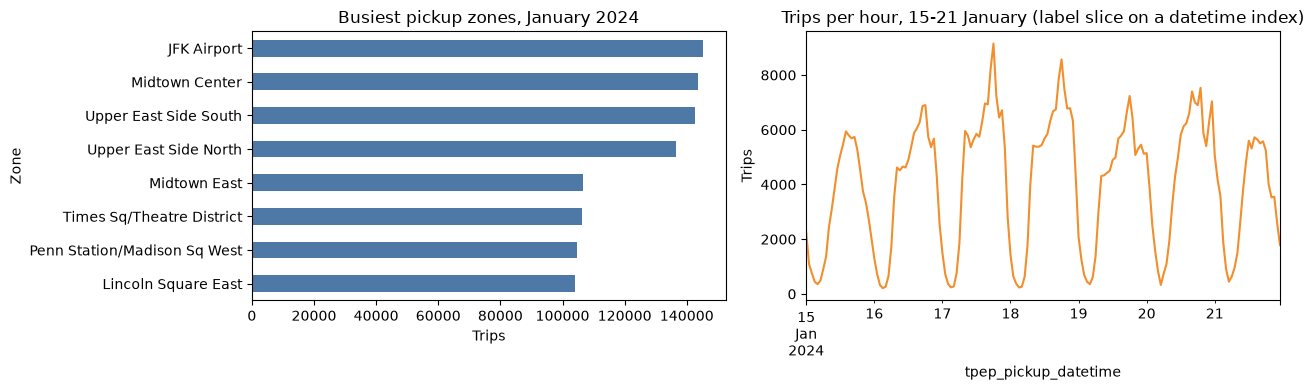

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
top_zones[::-1].plot.barh(ax=ax1, color="#4E79A7", title="Busiest pickup zones, January 2024")
ax1.set_xlabel("Trips")
by_time.loc["2024-01-15":"2024-01-21"].resample("h").size().plot(ax=ax2, color="#F28E2B",
                                                                 title="Trips per hour, 15-21 January (label slice on a datetime index)")
ax2.set_ylabel("Trips")
plt.tight_layout()
plt.show()

## 6. Assign Values Safely

With Copy-on-Write (pandas 3), assign with `loc` on the DataFrame you want to change, in **one** step. `df.assign(new=...)` returns a new DataFrame with extra columns, which suits method chains.

In [8]:
sample = trips.head(1000).copy()
sample.loc[sample["passenger_count"] == 0, "passenger_count"] = np.nan        # 0 passengers is not a valid trip
sample = sample.assign(tip_pct=lambda d: (100 * d["tip_amount"] / d["fare_amount"]).round(1))
print("zero passengers left:", (sample["passenger_count"] == 0).sum(), "| new column:", sample["tip_pct"].head(3).tolist())

zero passengers left: 0 | new column: [0.0, 37.5, 12.9]


*Insight: Use `loc` for labels and conditions, `iloc` for positions, and never chain two indexers to assign a value. For repeated lookups or time ranges, set and sort a meaningful index first.*

## Real-World Use Case or Analogy

`loc` is like finding a book **by its title** on a labelled shelf; `iloc` is like taking **the fifth book from the left**. A sorted index is the alphabetical order of the shelf: you jump straight to the right place instead of reading every spine.

Operations teams filter trips by zone and hour to plan fleets; fraud teams filter transactions above a threshold; analysts slice time ranges for reports. The same patterns appear in SQL (`WHERE`, M07) and Polars (`filter`, Lesson 16).